<a href="https://colab.research.google.com/github/nicolas-pueyo/ia-explicable/blob/main/notebooks/proyecto_iax.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys
if 'google.colab' in sys.modules:
  !pip install -q dtreeviz
!pip install interpret six graphviz pydotplus


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.3/102.3 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 43.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 83.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 105.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 88.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 70.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 800.1/800.1 kB 48.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 78.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.6/270.6 kB 19.6 MB/s eta 0:00:00
  Created wheel for dash-cytoscape: filename=dash_cytoscape-1.0.2-py3-none-any.whl size=4010811 sha256=f15b3bdcb7441f598ea6b3fe1ebb26544f058956176594ad4675083f0c0f5487


Carga de datos

In [2]:
import pandas as pd

base = "https://raw.githubusercontent.com/nicolas-pueyo/ia-explicable/main/data/"
train = pd.read_csv(base + "train.csv")
test = pd.read_csv(base + "test.csv")
dic = pd.read_excel(base + "data-dictionary.xlsx")

id_col = 'row_id'
target_col = 'payment_difficulty_next_month'

credit_y = train[target_col]
credit_X = train.drop(columns=[target_col, id_col])

categorical_cols = [
    'sex',
    'education',
    'marital_status',
    'repayment_assistance_plan'
]

numeric_cols = [col for col in credit_X.columns if col not in categorical_cols]

Preprocesado

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols)
    ]
)

tree_clf = DecisionTreeClassifier(random_state=42)

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", tree_clf)
])

Búsqueda de hiperparámetros

In [4]:
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    'classifier__max_depth': [3, 4], # valores pequeños para interpretabilidad
    'classifier__min_samples_leaf': [20, 50, 100],
    'classifier__criterion': ['gini', 'entropy']
}

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    refit=True # Entrena un modelo final con los mejores parámetros utilizando todo el conjunto de entrenamiento
)

grid_search.fit(credit_X, credit_y)
best_pipeline = grid_search.best_estimator_

In [5]:
# Mostrar los mejores hiperparámetros encontrados por el Grid Search
print("==================================================")
print("  MEJORES HIPERPARÁMETROS SELECCIONADOS POR CV")
print("==================================================")
for param, value in grid_search.best_params_.items():
    # Limpiamos el prefijo del clasificador para que sea más legible
    clean_param = param.replace('classifier__', '')
    print(f"-> {clean_param}: {value}")
print("==================================================")
print(f"Mejor puntuación obtenida (ROC AUC): {grid_search.best_score_:.4f}")

  MEJORES HIPERPARÁMETROS SELECCIONADOS POR CV
-> criterion: entropy
-> max_depth: 4
-> min_samples_leaf: 100
Mejor puntuación obtenida (ROC AUC): 0.7473


Resultados de la búsqueda

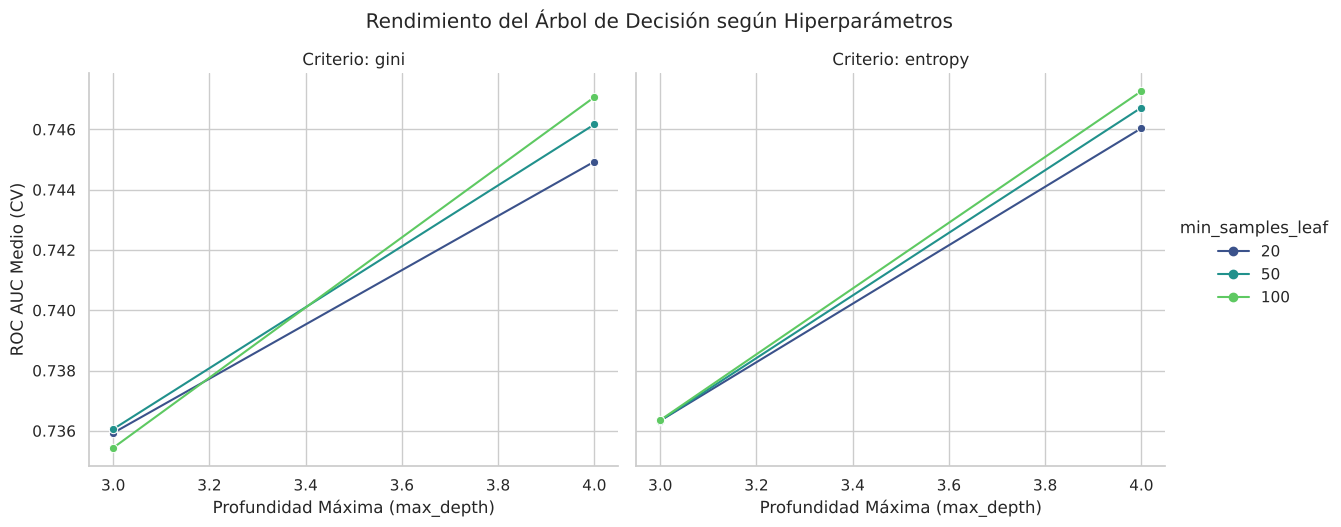

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

results_df = pd.DataFrame(grid_search.cv_results_)

results_df['max_depth'] = results_df['param_classifier__max_depth'].astype(int)
results_df['min_samples_leaf'] = results_df['param_classifier__min_samples_leaf'].astype(str)
results_df['criterion'] = results_df['param_classifier__criterion']
results_df['roc_auc'] = results_df['mean_test_score']

sns.set_theme(style="whitegrid")
g = sns.relplot(
    data=results_df,
    kind="line",
    x="max_depth",
    y="roc_auc",
    hue="min_samples_leaf",
    col="criterion",
    marker="o",
    height=5,
    aspect=1.2,
    palette="viridis"
)

g.set_axis_labels("Profundidad Máxima (max_depth)", "ROC AUC Medio (CV)")
g.set_titles("Criterio: {col_name}")
g.fig.suptitle("Rendimiento del Árbol de Decisión según Hiperparámetros", y=1.05)

plt.savefig("hyperparameter_tuning.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
tabla_grid = pd.DataFrame(grid_search.cv_results_)[[
    "param_classifier__criterion",
    "param_classifier__max_depth",
    "param_classifier__min_samples_leaf",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]]
tabla_grid.columns = ["criterion", "max_depth", "min_samples_leaf", "ROC-AUC medio", "Desv. típica", "Ranking"]
tabla_grid = tabla_grid.sort_values("Ranking").round(4).reset_index(drop=True)
tabla_grid

,criterion,max_depth,min_samples_leaf,ROC-AUC medio,Desv. típica,Ranking
0,entropy,4,100,0.7473,0.0050,1
1,gini,4,100,0.7471,0.0045,2
2,entropy,4,50,0.7467,0.0044,3
3,gini,4,50,0.7462,0.0052,4
4,entropy,4,20,0.7460,0.0051,5
5,gini,4,20,0.7449,0.0049,6
6,entropy,3,100,0.7364,0.0056,7
7,entropy,3,20,0.7363,0.0056,8
8,entropy,3,50,0.7363,0.0056,8
9,gini,3,50,0.7361,0.0047,10


Árbol resultante

Reglas lógicas del modelo óptimo:
|--- latest_repayment_status <= 0.50
|   |--- payment_to_bill_ratio_6m <= 0.11
|   |   |--- zero_payment_months_6m <= 3.50
|   |   |   |--- age <= 24.50
|   |   |   |   |--- class: 0
|   |   |   |--- age >  24.50
|   |   |   |   |--- class: 0
|   |   |--- zero_payment_months_6m >  3.50
|   |   |   |--- payment_to_bill_ratio_6m <= 0.01
|   |   |   |   |--- class: 0
|   |   |   |--- payment_to_bill_ratio_6m >  0.01
|   |   |   |   |--- class: 0
|   |--- payment_to_bill_ratio_6m >  0.11
|   |   |--- zero_payment_months_6m <= 2.50
|   |   |   |--- payment_to_bill_ratio_6m <= 0.25
|   |   |   |   |--- class: 0
|   |   |   |--- payment_to_bill_ratio_6m >  0.25
|   |   |   |   |--- class: 0
|   |   |--- zero_payment_months_6m >  2.50
|   |   |   |--- payment_to_bill_ratio_6m <= 1.29
|   |   |   |   |--- class: 0
|   |   |   |--- payment_to_bill_ratio_6m >  1.29
|   |   |   |   |--- class: 0
|--- latest_repayment_status >  0.50
|   |--- payment_to_bill_ratio_6

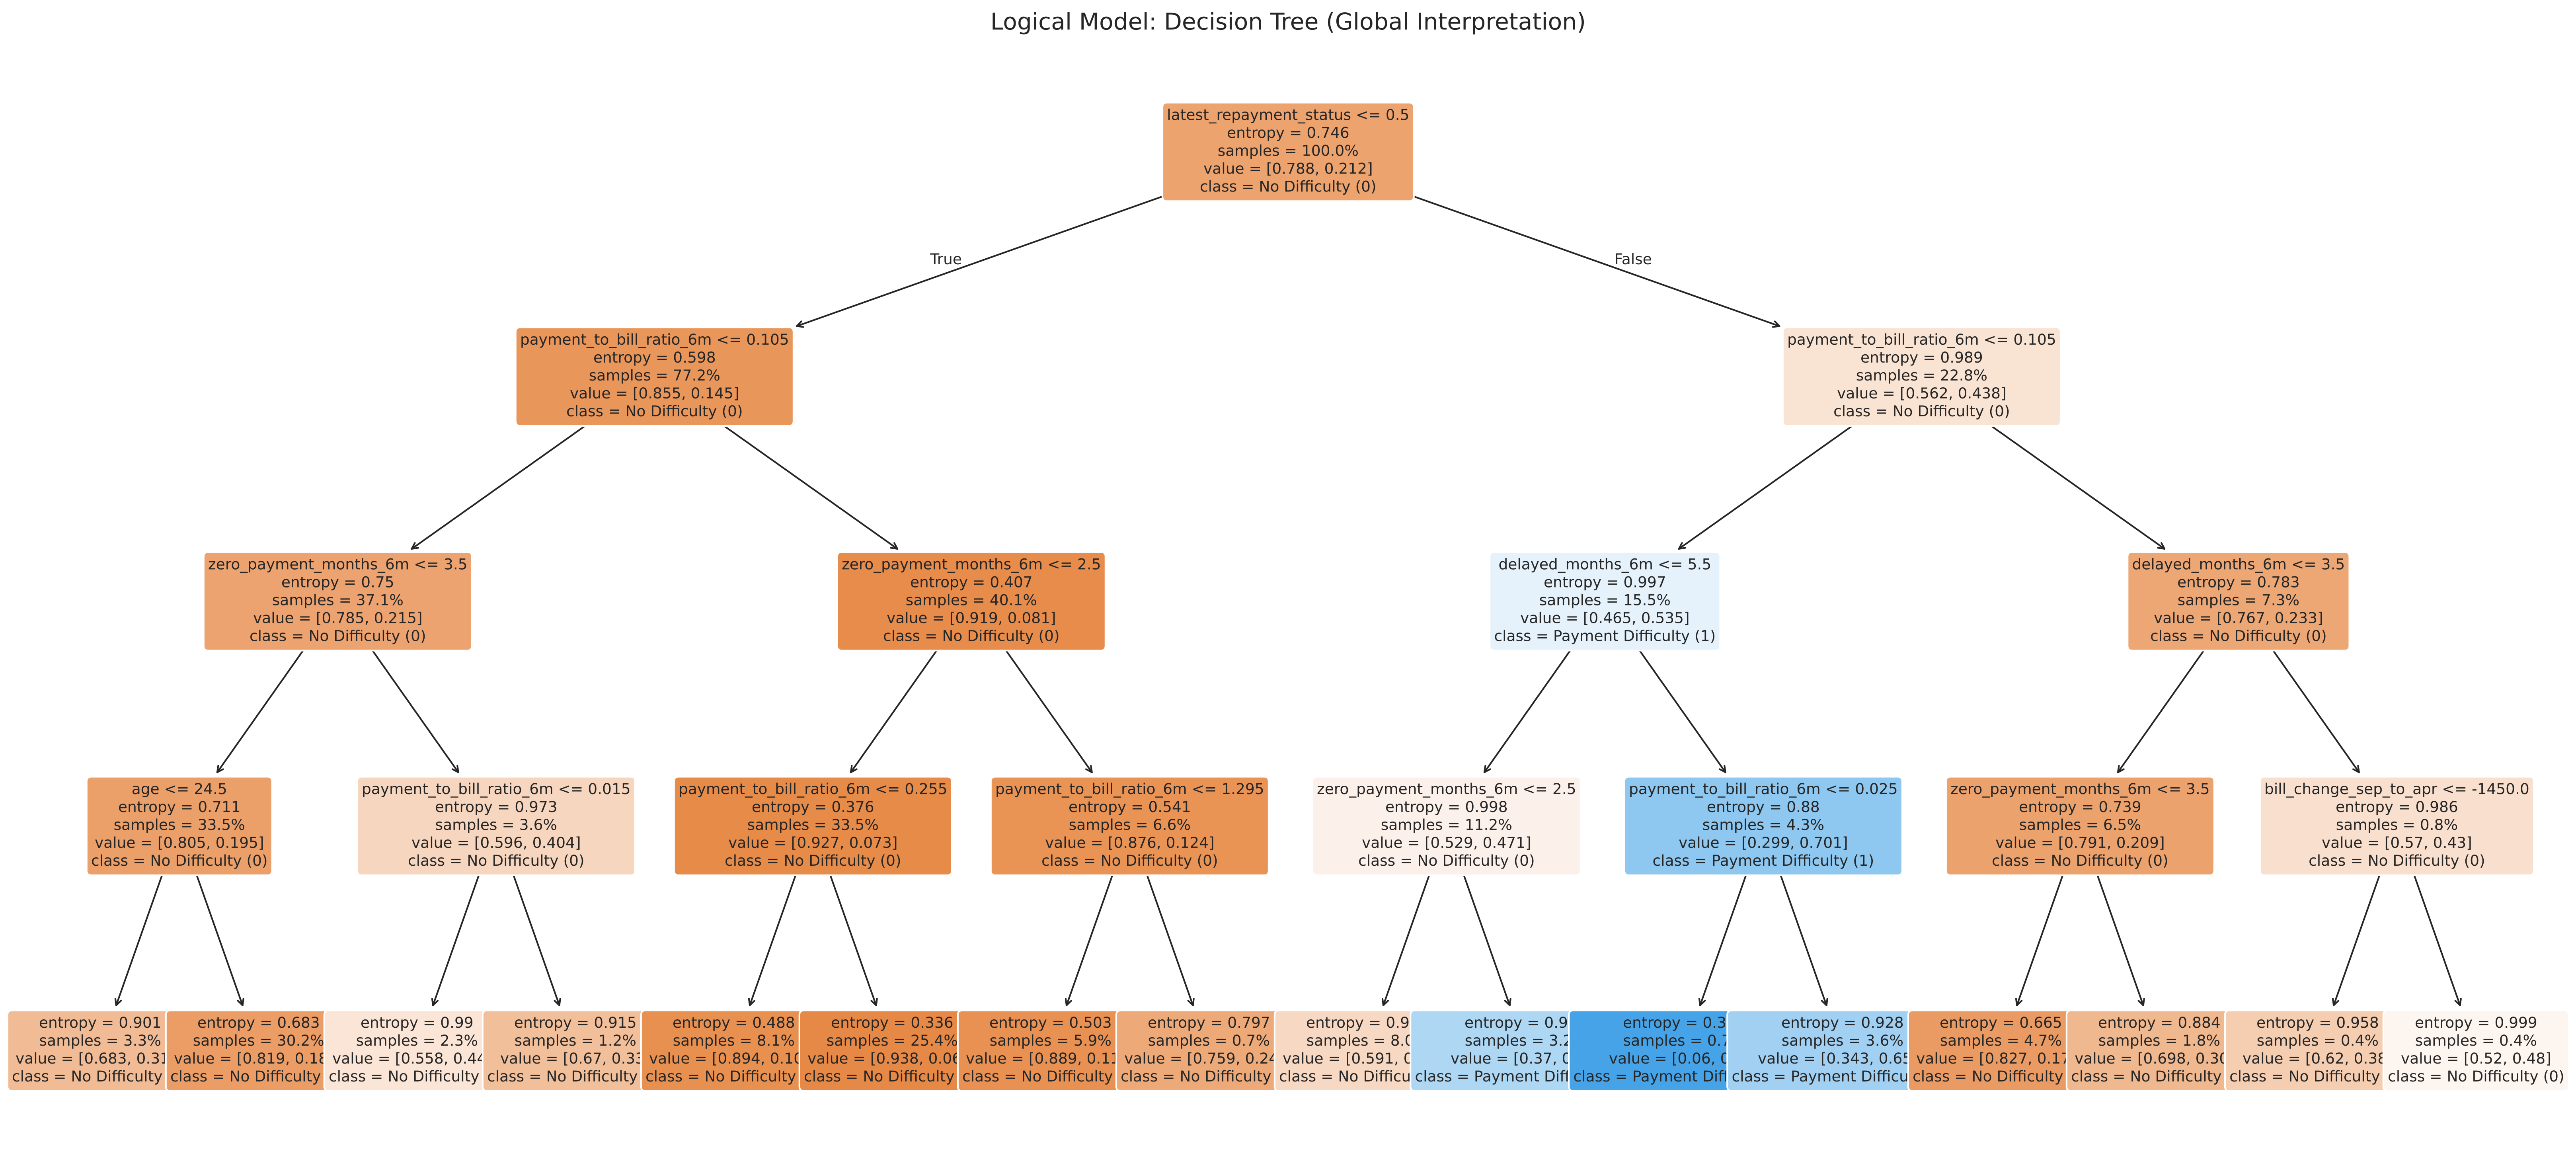

In [8]:
from sklearn.tree import export_text, plot_tree

fitted_tree = best_pipeline.named_steps["classifier"]
feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
clean_feature_names = [col.replace("cat__", "").replace("num__", "") for col in feature_names]

print("Reglas lógicas del modelo óptimo:")
print(export_text(fitted_tree, feature_names=clean_feature_names))

plt.figure(figsize=(22, 10), dpi=300)
plot_tree(
    fitted_tree,
    feature_names=clean_feature_names,
    class_names=["No Difficulty (0)", "Payment Difficulty (1)"],
    filled=True,
    rounded=True,
    fontsize=9,
    impurity=True,
    proportion=True,
)
plt.title("Logical Model: Decision Tree (Global Interpretation)", fontsize=14)
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=300, bbox_inches="tight")

Métricas de rendimiento

In [9]:
scoring_metrics = ["accuracy", "balanced_accuracy", "recall", "roc_auc"]
cv_results = cross_validate(
    best_pipeline,
    credit_X,
    credit_y,
    cv=cv,
    scoring=scoring_metrics,
    return_train_score=False
)

for metric in scoring_metrics:
    mean_val = cv_results[f"test_{metric}"].mean()
    std_val = cv_results[f"test_{metric}"].std()
    print(f"{metric}: {mean_val:.4f} (+/- {std_val:.4f})")

accuracy: 0.8128 (+/- 0.0022)
balanced_accuracy: 0.6026 (+/- 0.0040)
recall: 0.2374 (+/- 0.0077)
roc_auc: 0.7473 (+/- 0.0050)


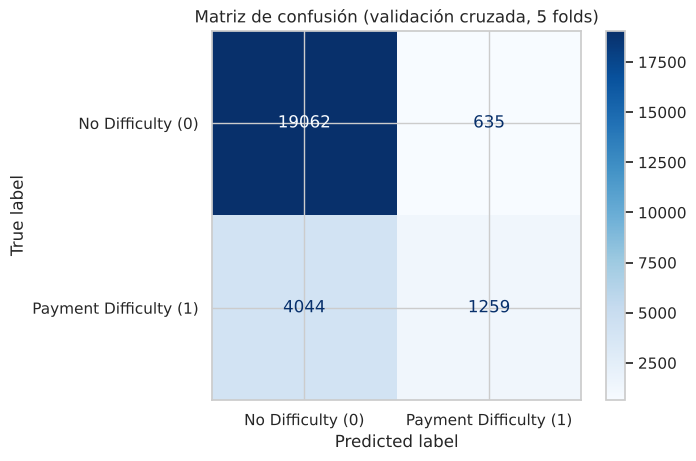

In [10]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

# Predicciones fuera de fold: cada instancia es predicha por el modelo que no la vio en entrenamiento
y_pred_cv = cross_val_predict(best_pipeline, credit_X, credit_y, cv=cv)

ConfusionMatrixDisplay.from_predictions(
    credit_y, y_pred_cv,
    display_labels=["No Difficulty (0)", "Payment Difficulty (1)"],
    cmap="Blues", values_format="d"
)
plt.title("Matriz de confusión (validación cruzada, 5 folds)")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

Interpretacion global

In [11]:
fitted_tree = best_pipeline.named_steps["classifier"]
feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
clean_feature_names = [col.replace("cat__", "").replace("num__", "") for col in feature_names]

Interpretación local

In [12]:
from interpret.glassbox import ClassificationTree
from interpret import show
import pandas as pd
import numpy as np

# Extraer los hiperparámetros óptimos que encontró Grid Search
best_params = grid_search.best_params_
opt_max_depth = best_params['classifier__max_depth']
opt_min_samples_leaf = best_params['classifier__min_samples_leaf']
opt_criterion = best_params['classifier__criterion']

# Transformar el conjunto de entrenamiento
X_train_trans = best_pipeline.named_steps["preprocessor"].transform(credit_X)
if hasattr(X_train_trans, "toarray"):
    X_train_trans = X_train_trans.toarray()

X_train_df = pd.DataFrame(X_train_trans, columns=clean_feature_names)

# Entrenar el árbol de InterpretML con la configuración óptima
interpret_tree = ClassificationTree(
    max_depth=opt_max_depth,
    min_samples_leaf=opt_min_samples_leaf,
    criterion=opt_criterion,
    random_state=42
)
interpret_tree.fit(X_train_df, credit_y)

# Obtener las predicciones del modelo para identificar aciertos y errores
y_pred = best_pipeline.predict(credit_X)

# Definir las condiciones para cada uno de los 4 casos solicitados
mask_c0_correct = (y_pred == 0) & (credit_y == 0)
mask_c0_incorrect = (y_pred == 1) & (credit_y == 0)
mask_c1_correct = (y_pred == 1) & (credit_y == 1)
mask_c1_incorrect = (y_pred == 0) & (credit_y == 1)

# Seleccionar la primera instancia que cumpla cada condición
idx_c0_correct = credit_X[mask_c0_correct].index[0]
idx_c0_incorrect = credit_X[mask_c0_incorrect].index[0]
idx_c1_correct = credit_X[mask_c1_correct].index[0]
idx_c1_incorrect = credit_X[mask_c1_incorrect].index[0]

# Crear un DataFrame con las 4 instancias seleccionadas y renombrar el índice para el gráfico
instancias_locales = credit_X.loc[[idx_c0_correct, idx_c0_incorrect, idx_c1_correct, idx_c1_incorrect]].copy()
instancias_locales.index = [
    'Clase 0 - Prediccion Correcta (True Neg)',
    'Clase 0 - Prediccion Incorrecta (False Pos)',
    'Clase 1 - Prediccion Correcta (True Pos)',
    'Clase 1 - Prediccion Incorrecta (False Neg)'
]

y_locales = credit_y.loc[[idx_c0_correct, idx_c0_incorrect, idx_c1_correct, idx_c1_incorrect]]
y_locales.index = instancias_locales.index

# Transformar las instancias pasando por el preprocesador
X_locales_trans = best_pipeline.named_steps["preprocessor"].transform(instancias_locales)
if hasattr(X_locales_trans, "toarray"):
    X_locales_trans = X_locales_trans.toarray()

X_locales_df = pd.DataFrame(X_locales_trans, columns=clean_feature_names, index=instancias_locales.index)

# Generar y mostrar la explicación local (Widget con desplegable para los 4 casos)
tree_local = interpret_tree.explain_local(X_locales_df, y_locales, name='Comparativa de Predicciones Locales')
show(tree_local)

<!-- http://127.0.0.1:7001/140061641442032/ -->

In [13]:
train["payment_difficulty_next_month"].value_counts(normalize=True)

payment_difficulty_next_month
0    0.78788
1    0.21212
Name: proportion, dtype: float64

# Regresión logística

En la regresión logística el *log-odds* de tener dificultades de pago se modela como una combinación lineal de las variables:

$$\log\frac{P(y=1\mid x)}{1-P(y=1\mid x)} = \beta_0 + \sum_i \beta_i x_i$$

Cada coeficiente $\beta_i$ representa la relación entre la variable $x_i$ y el objetivo **manteniendo constantes el resto de variables** (dependencia condicional), no la relación marginal que veríamos al cruzar $x_i$ con la tasa de impagos. Además, cualquier conclusión se refiere al modelo aprendido, no al proceso real que genera los datos.

In [14]:
import numpy as np
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

## Primer modelo: casi sin regularización y sin escalar

Como primera aproximación reutilizamos el mismo preprocesado que en el árbol (one-hot de las categóricas y variables numéricas tal cual) y ajustamos una regresión logística con una regularización muy pequeña (`C` muy grande).

In [15]:
lr_raw_pipeline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(C=1e6, solver="newton-cholesky", max_iter=1000))
])
lr_raw_pipeline.fit(credit_X, credit_y)

lr_feature_names = [
    col.replace("cat__", "").replace("num__", "")
    for col in lr_raw_pipeline.named_steps["preprocessor"].get_feature_names_out()
]

coefs_raw = pd.DataFrame(
    lr_raw_pipeline.named_steps["classifier"].coef_[0],
    columns=["Coeficiente"],
    index=lr_feature_names,
)
coefs_raw

,Coeficiente
sex_male,-7.063919e-02
education_high_school,8.263100e-02
education_other,-2.474450e-01
education_university,-4.568453e-02
education_unknown,8.227886e-02
marital_status_other_or_unknown,-1.327952e-01
marital_status_single,3.090997e-02
repayment_assistance_plan_yes,4.620496e-01
credit_limit,5.328302e-07
age,-1.163729e-02


## Interpretación de coeficientes: la escala importa

Cada coeficiente está expresado en "log-odds por unidad de la variable": el de `credit_limit` es por cada NTD de límite, el de `age` por cada año y los de las dummies por pasar de 0 a 1. Por eso no podemos comparar sus magnitudes directamente.

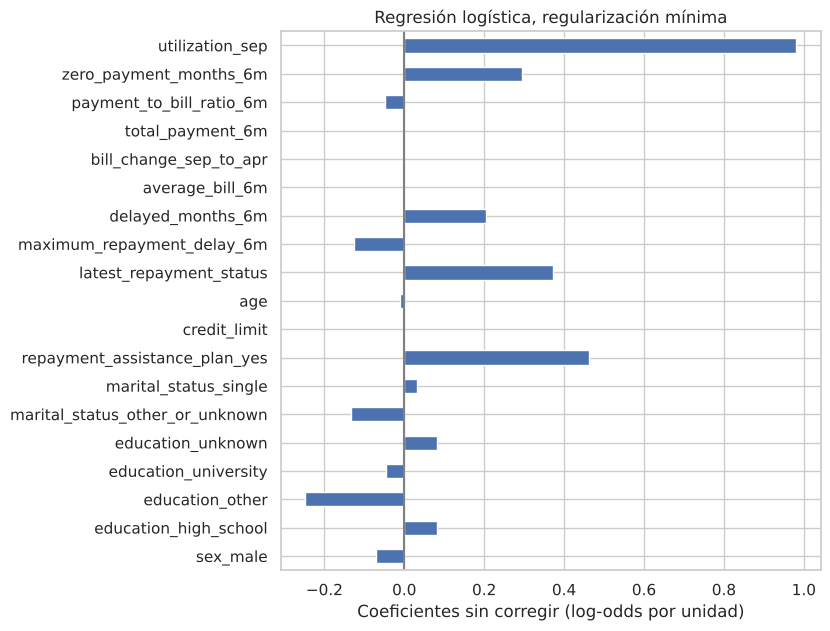

In [16]:
coefs_raw.plot.barh(figsize=(9, 7), legend=False)
plt.title("Regresión logística, regularización mínima")
plt.axvline(x=0, color=".5")
plt.xlabel("Coeficientes sin corregir (log-odds por unidad)")
plt.subplots_adjust(left=0.3)

Las variables tienen escalas muy distintas, como se ve en sus desviaciones típicas:

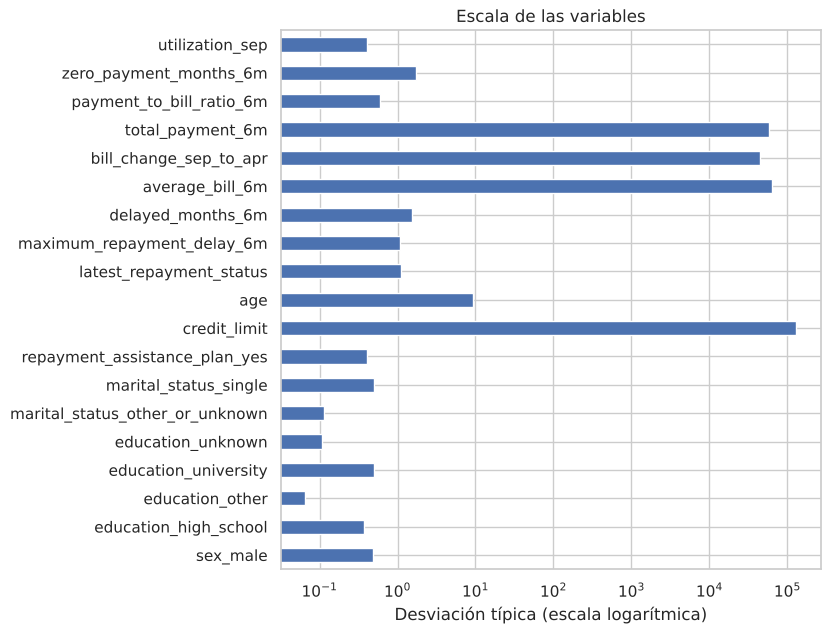

In [17]:
X_lr_raw = pd.DataFrame(
    lr_raw_pipeline.named_steps["preprocessor"].transform(credit_X),
    columns=lr_feature_names,
)

X_lr_raw.std(axis=0).plot.barh(figsize=(9, 7), logx=True)
plt.title("Escala de las variables")
plt.xlabel("Desviación típica (escala logarítmica)")
plt.subplots_adjust(left=0.3)

Multiplicando cada coeficiente por la desviación típica de su variable los llevamos todos a la misma unidad (cambio en log-odds por una desviación típica), ya que $\sum_i \beta_i x_i = \sum_i (\beta_i \sigma_i)(x_i/\sigma_i)$.

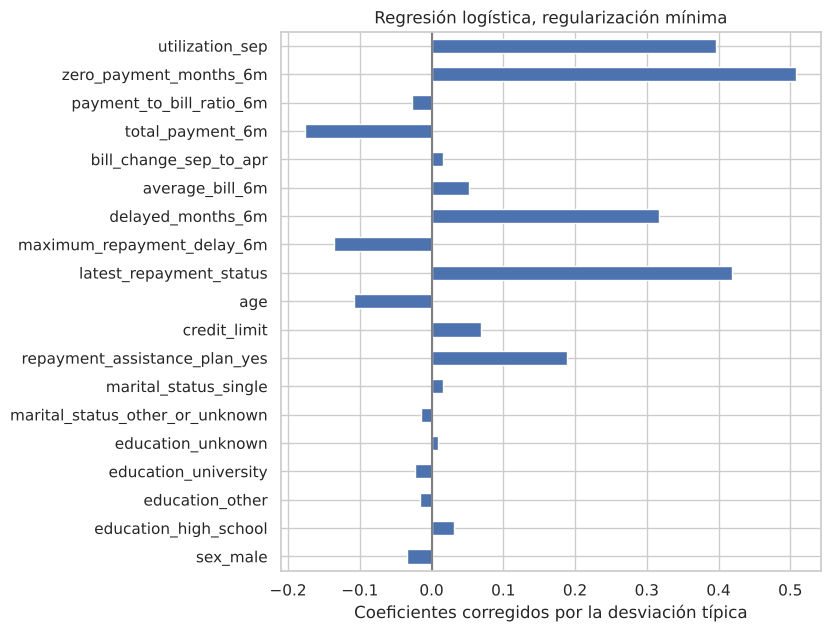

In [18]:
coefs_corr = pd.DataFrame(
    lr_raw_pipeline.named_steps["classifier"].coef_[0] * X_lr_raw.std(axis=0),
    columns=["Importancia del coeficiente"],
    index=lr_feature_names,
)
coefs_corr.plot.barh(figsize=(9, 7), legend=False)
plt.xlabel("Coeficientes corregidos por la desviación típica")
plt.title("Regresión logística, regularización mínima")
plt.axvline(x=0, color=".5")
plt.subplots_adjust(left=0.3)

## Preprocesado con estandarización

En lugar de corregir los coeficientes a posteriori, estandarizamos las variables numéricas dentro del pipeline. Así la penalización actúa por igual sobre todas las variables y los coeficientes son directamente comparables. El escalado se ajusta dentro de cada fold de la validación cruzada.

In [19]:
lr_preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),
        ("num", StandardScaler(), numeric_cols)
    ]
)

lr_clf = LogisticRegression(penalty="elasticnet", solver="saga", max_iter=5000, random_state=42)

lr_pipeline = Pipeline(steps=[
    ("preprocessor", lr_preprocessor),
    ("classifier", lr_clf)
])

## Búsqueda de hiperparámetros

Buscamos con la misma validación cruzada de 5 folds que en el árbol:

- `C`: inversa de la fuerza de regularización (cuanto menor, más regularización).
- `l1_ratio`: 0 equivale a ridge (L2), 1 a lasso (L1) y valores intermedios a elastic net.

In [20]:
param_grid_lr = {
    'classifier__C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100],
    'classifier__l1_ratio': [0, 0.5, 1]
}

grid_search_lr = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid_lr,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    refit=True
)

grid_search_lr.fit(credit_X, credit_y)
best_pipeline_lr = grid_search_lr.best_estimator_

In [21]:
print("==================================================")
print("  MEJORES HIPERPARÁMETROS SELECCIONADOS POR CV")
print("==================================================")
for param, value in grid_search_lr.best_params_.items():
    clean_param = param.replace('classifier__', '')
    print(f"-> {clean_param}: {value}")
print("==================================================")
print(f"Mejor puntuación obtenida (ROC AUC): {grid_search_lr.best_score_:.4f}")

  MEJORES HIPERPARÁMETROS SELECCIONADOS POR CV
-> C: 0.1
-> l1_ratio: 0
Mejor puntuación obtenida (ROC AUC): 0.7518


Resultados de la búsqueda

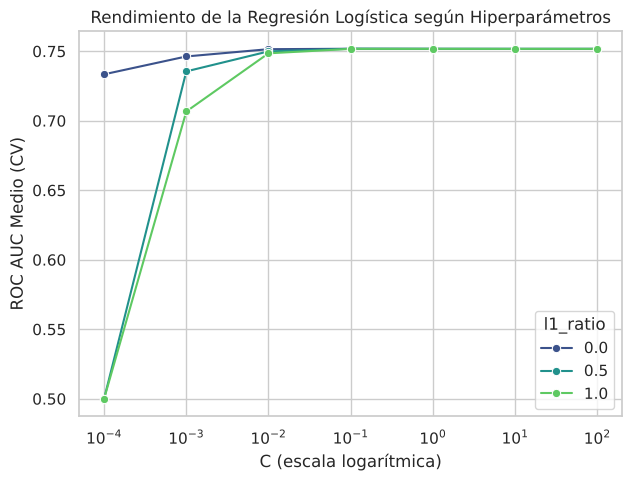

In [22]:
results_lr_df = pd.DataFrame(grid_search_lr.cv_results_)
results_lr_df['C'] = results_lr_df['param_classifier__C'].astype(float)
results_lr_df['l1_ratio'] = results_lr_df['param_classifier__l1_ratio'].astype(str)
results_lr_df['roc_auc'] = results_lr_df['mean_test_score']

plt.figure(figsize=(7, 5))
sns.lineplot(data=results_lr_df, x="C", y="roc_auc", hue="l1_ratio", marker="o", palette="viridis")
plt.xscale("log")
plt.xlabel("C (escala logarítmica)")
plt.ylabel("ROC AUC Medio (CV)")
plt.title("Rendimiento de la Regresión Logística según Hiperparámetros")
plt.savefig("lr_hyperparameter_tuning.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
tabla_grid_lr = pd.DataFrame(grid_search_lr.cv_results_)[[
    "param_classifier__C",
    "param_classifier__l1_ratio",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]]
tabla_grid_lr.columns = ["C", "l1_ratio", "ROC-AUC medio", "Desv. típica", "Ranking"]
tabla_grid_lr = tabla_grid_lr.sort_values("Ranking").round(4).reset_index(drop=True)
tabla_grid_lr

,C,l1_ratio,ROC-AUC medio,Desv. típica,Ranking
0,0.1000,0.0,0.7518,0.0055,1
1,0.1000,0.5,0.7518,0.0054,2
2,1.0000,0.5,0.7517,0.0056,3
3,1.0000,1.0,0.7517,0.0056,4
4,1.0000,0.0,0.7517,0.0056,5
5,0.1000,1.0,0.7517,0.0054,6
6,10.0000,0.5,0.7517,0.0057,7
7,10.0000,1.0,0.7517,0.0057,8
8,10.0000,0.0,0.7517,0.0057,9
9,100.0000,1.0,0.7517,0.0057,10


Para cualquier `C` a partir de 0.01 el ROC AUC es prácticamente el mismo (≈0.752) con cualquier tipo de penalización: con 25 000 instancias y 19 variables, la regularización apenas cambia el rendimiento. Solo con `C` muy pequeños el modelo empeora; con L1 llega incluso a anular todos los coeficientes (AUC = 0.5). La búsqueda elige ridge (`l1_ratio=0`) con `C=0.1`, ligeramente mejor que el resto.

Métricas de rendimiento

In [24]:
cv_results_lr = cross_validate(
    best_pipeline_lr,
    credit_X,
    credit_y,
    cv=cv,
    scoring=scoring_metrics,
    return_train_score=False
)

for metric in scoring_metrics:
    mean_val = cv_results_lr[f"test_{metric}"].mean()
    std_val = cv_results_lr[f"test_{metric}"].std()
    print(f"{metric}: {mean_val:.4f} (+/- {std_val:.4f})")

accuracy: 0.8106 (+/- 0.0031)
balanced_accuracy: 0.6038 (+/- 0.0062)
recall: 0.2446 (+/- 0.0118)
roc_auc: 0.7518 (+/- 0.0055)


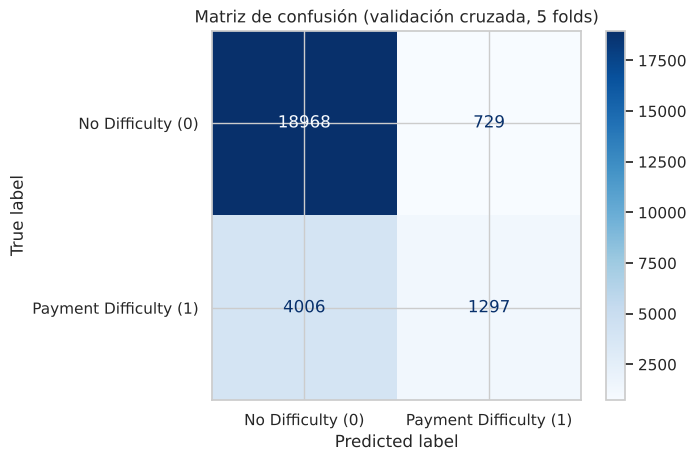

In [25]:
y_pred_cv_lr = cross_val_predict(best_pipeline_lr, credit_X, credit_y, cv=cv)

ConfusionMatrixDisplay.from_predictions(
    credit_y, y_pred_cv_lr,
    display_labels=["No Difficulty (0)", "Payment Difficulty (1)"],
    cmap="Blues", values_format="d"
)
plt.title("Matriz de confusión (validación cruzada, 5 folds)")
plt.savefig("lr_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## Elección del umbral de clasificación

Por defecto el modelo predice la clase 1 cuando la probabilidad estimada supera 0.5. Con solo un 21 % de positivos, ese umbral deja escapar muchos casos con dificultades. Elegimos el umbral también con validación cruzada de 5 folds, usando las probabilidades fuera de fold (cada instancia la predice un modelo que no la ha visto).

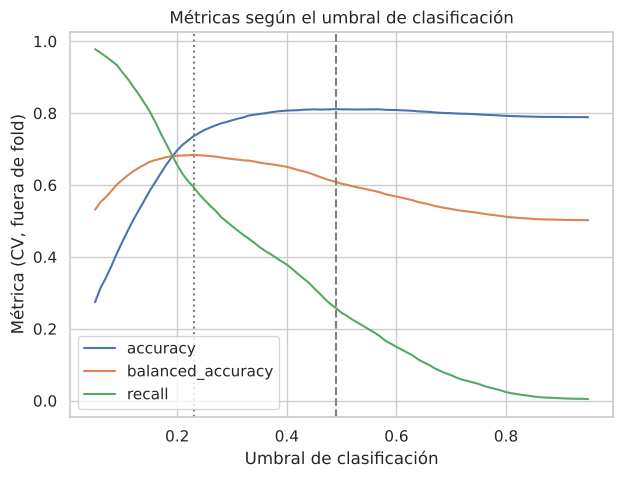

Umbral que maximiza accuracy: 0.49
Umbral que maximiza balanced accuracy: 0.23


,umbral,accuracy,balanced_accuracy,recall
18,0.23,0.7363,0.6844,0.5942
44,0.49,0.8111,0.6086,0.2570
45,0.50,0.8106,0.6038,0.2446


In [26]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score

proba_cv_lr = cross_val_predict(best_pipeline_lr, credit_X, credit_y, cv=cv, method="predict_proba")[:, 1]

umbrales = np.round(np.arange(0.05, 0.951, 0.01), 2)
curva_umbral = pd.DataFrame({
    "umbral": umbrales,
    "accuracy": [accuracy_score(credit_y, proba_cv_lr >= u) for u in umbrales],
    "balanced_accuracy": [balanced_accuracy_score(credit_y, proba_cv_lr >= u) for u in umbrales],
    "recall": [recall_score(credit_y, proba_cv_lr >= u) for u in umbrales],
})

umbral_acc = curva_umbral.loc[curva_umbral["accuracy"].idxmax(), "umbral"]
umbral_bal = curva_umbral.loc[curva_umbral["balanced_accuracy"].idxmax(), "umbral"]

plt.figure(figsize=(7, 5))
for metric in ["accuracy", "balanced_accuracy", "recall"]:
    plt.plot(curva_umbral["umbral"], curva_umbral[metric], label=metric)
plt.axvline(umbral_acc, color=".5", linestyle="--")
plt.axvline(umbral_bal, color=".5", linestyle=":")
plt.xlabel("Umbral de clasificación")
plt.ylabel("Métrica (CV, fuera de fold)")
plt.title("Métricas según el umbral de clasificación")
plt.legend()
plt.savefig("lr_threshold.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Umbral que maximiza accuracy: {umbral_acc}")
print(f"Umbral que maximiza balanced accuracy: {umbral_bal}")
curva_umbral[curva_umbral["umbral"].isin([0.5, umbral_acc, umbral_bal])].round(4)

El umbral que maximiza el accuracy está prácticamente en 0.5 (≈0.81, frente al 0.79 de predecir siempre la clase mayoritaria). Si el objetivo es detectar clientes con dificultades, el umbral que maximiza el balanced accuracy (≈0.23) sube el recall de ≈0.25 a ≈0.59, a costa de más falsos positivos y menos accuracy. El umbral depende del coste relativo de cada tipo de error. Para las predicciones de `test.csv`, que se evalúan con accuracy, conviene el umbral cercano a 0.5.

Respecto al árbol (ROC AUC 0.747, accuracy 0.813), la regresión logística tiene un ROC AUC algo mayor (0.752) y un accuracy similar.

## Interpretación global

Como las variables numéricas están estandarizadas, cada coeficiente es el cambio en log-odds cuando la variable aumenta una desviación típica (o cuando una categórica pasa de la categoría de referencia a la indicada), con el resto de variables fijas. $e^{\beta_i}$ es el factor por el que se multiplican las odds.

In [27]:
lr_std_feature_names = [
    col.replace("cat__", "").replace("num__", "")
    for col in best_pipeline_lr.named_steps["preprocessor"].get_feature_names_out()
]
fitted_lr = best_pipeline_lr.named_steps["classifier"]

coefs_lr = pd.DataFrame({
    "Coeficiente": fitted_lr.coef_[0],
    "Odds ratio": np.exp(fitted_lr.coef_[0]),
}, index=lr_std_feature_names)
coefs_lr = coefs_lr.reindex(coefs_lr["Coeficiente"].abs().sort_values(ascending=False).index)

print(f"Intercepto: {fitted_lr.intercept_[0]:.4f} (probabilidad base: {1 / (1 + np.exp(-fitted_lr.intercept_[0])):.3f})")
coefs_lr.round(4)

Intercepto: -1.6366 (probabilidad base: 0.163)


,Coeficiente,Odds ratio
zero_payment_months_6m,0.5058,1.6583
repayment_assistance_plan_yes,0.4556,1.5771
latest_repayment_status,0.4162,1.5162
utilization_sep,0.3924,1.4805
delayed_months_6m,0.3149,1.3702
total_payment_6m,-0.1745,0.8399
education_other,-0.1346,0.8741
maximum_repayment_delay_6m,-0.1317,0.8766
marital_status_other_or_unknown,-0.1082,0.8975
age,-0.1068,0.8987


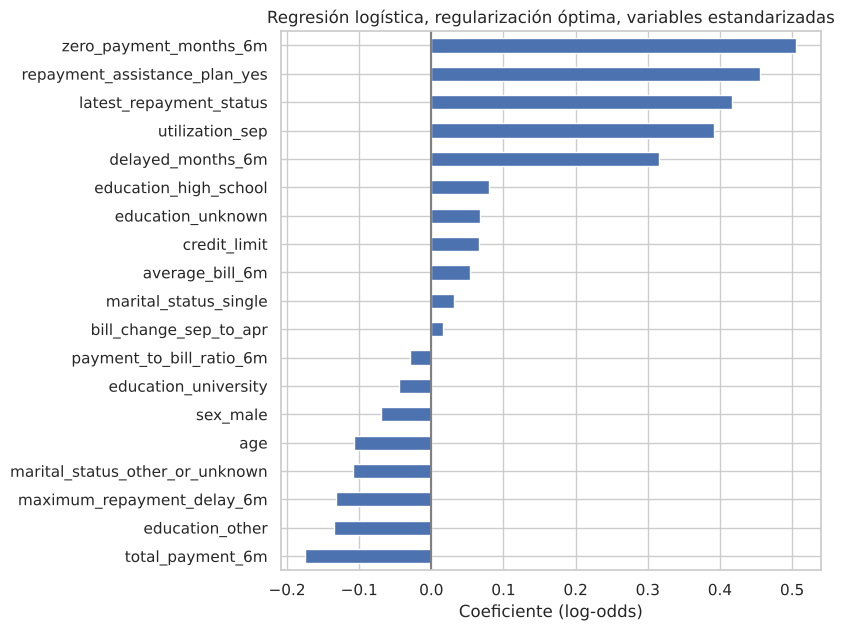

In [28]:
coefs_lr["Coeficiente"].sort_values().plot.barh(figsize=(9, 7))
plt.title("Regresión logística, regularización óptima, variables estandarizadas")
plt.xlabel("Coeficiente (log-odds)")
plt.axvline(x=0, color=".5")
plt.subplots_adjust(left=0.3)
plt.savefig("lr_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()

- Las variables que más aumentan el riesgo son las del historial de pago: `zero_payment_months_6m` (cada desviación típica más multiplica las odds por ≈1.66), `latest_repayment_status` (≈1.52), `utilization_sep` (≈1.48) y `delayed_months_6m` (≈1.37). Coincide con el árbol, que también se apoya sobre todo en el estado de pago más reciente, los meses sin pago y los retrasos.
- `repayment_assistance_plan_yes` tiene uno de los coeficientes más grandes (odds ≈1.58 veces mayores que sin plan), pero no debe leerse como un efecto causal (ver más abajo).
- Reducen el riesgo `total_payment_6m`, `age` y, sorprendentemente, `maximum_repayment_delay_6m`, cuya relación marginal con el objetivo es claramente positiva. Lo analizamos en la sección de variables correlacionadas.
- `payment_to_bill_ratio_6m` tiene un coeficiente casi nulo, mientras que en el árbol es la segunda variable más usada (con un corte en torno a 0.11). Su relación con el riesgo no es lineal y el modelo logístico no puede capturarla con un único coeficiente.
- Las variables demográficas (`sex`, `education`, `marital_status`) tienen coeficientes pequeños.
- El intercepto corresponde a la categoría de referencia (mujer, `graduate_school`, casada, sin plan) con todas las numéricas en su media: probabilidad ≈0.16.

## Variabilidad de los coeficientes

Comprobamos la estabilidad de los coeficientes repitiendo la validación cruzada de 5 folds con 5 particiones distintas. Si un coeficiente cambia mucho al perturbar los datos, debe interpretarse con cautela.

In [29]:
from sklearn.model_selection import RepeatedStratifiedKFold

cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
cv_model_lr = cross_validate(
    best_pipeline_lr,
    credit_X,
    credit_y,
    cv=cv_rep,
    return_estimator=True,
    n_jobs=-1,
)

coefs_cv_lr = pd.DataFrame(
    [est.named_steps["classifier"].coef_[0] for est in cv_model_lr["estimator"]],
    columns=lr_std_feature_names,
)

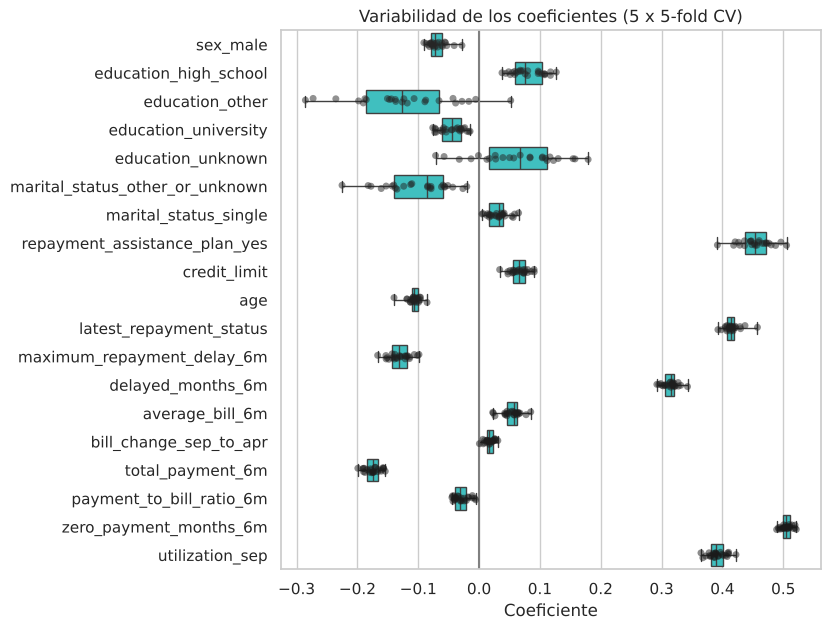

In [30]:
plt.figure(figsize=(9, 7))
sns.stripplot(data=coefs_cv_lr, orient="h", palette="dark:k", alpha=0.5)
sns.boxplot(data=coefs_cv_lr, orient="h", color="cyan", saturation=0.5, whis=10)
plt.axvline(x=0, color=".5")
plt.xlabel("Coeficiente")
plt.title("Variabilidad de los coeficientes (5 x 5-fold CV)")
plt.subplots_adjust(left=0.3)
plt.savefig("lr_coef_variability.png", dpi=300, bbox_inches="tight")
plt.show()

## El problema de las variables correlacionadas

Varias variables de historial de pago miden cosas muy parecidas. Cuando dos variables varían juntas, el modelo no puede separar bien sus efectos y sus coeficientes se compensan entre sí.

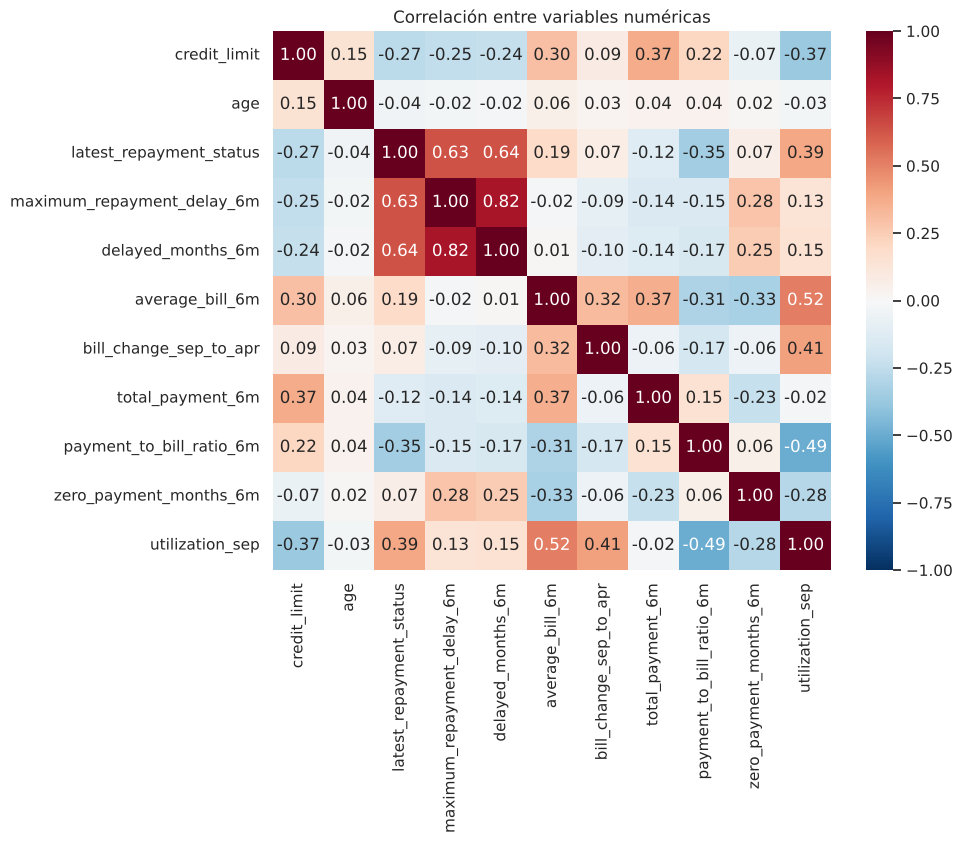

In [31]:
plt.figure(figsize=(9, 7))
sns.heatmap(credit_X[numeric_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas")
plt.show()

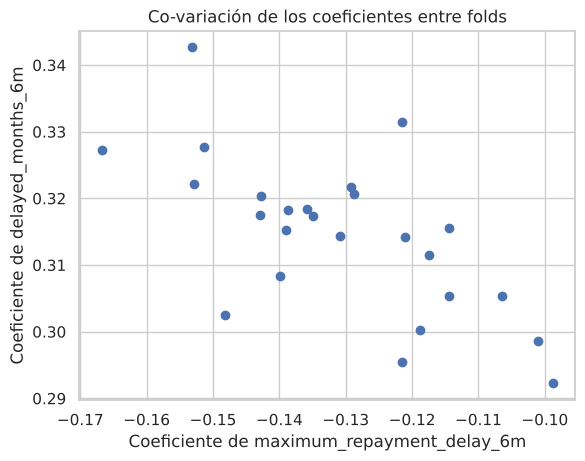

In [32]:
plt.scatter(coefs_cv_lr["maximum_repayment_delay_6m"], coefs_cv_lr["delayed_months_6m"])
plt.xlabel("Coeficiente de maximum_repayment_delay_6m")
plt.ylabel("Coeficiente de delayed_months_6m")
plt.grid(True)
_ = plt.title("Co-variación de los coeficientes entre folds")

Para comprobar el efecto de la colinealidad quitamos `maximum_repayment_delay_6m` y vemos cómo cambian el rendimiento y la estabilidad del resto de coeficientes.

ROC AUC con todas las variables: 0.7517
ROC AUC sin maximum_repayment_delay_6m: 0.7508


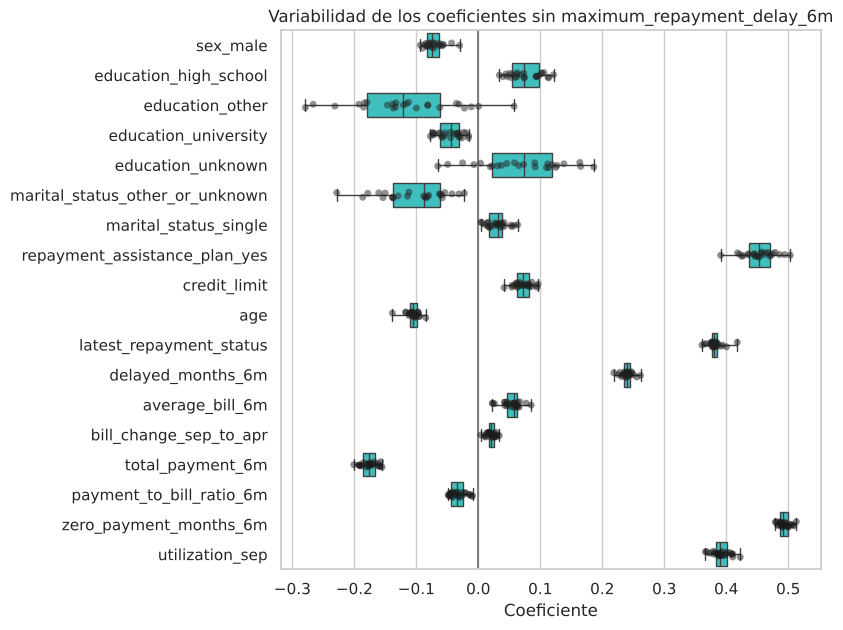

In [33]:
column_to_drop = ["maximum_repayment_delay_6m"]
numeric_cols_drop = [col for col in numeric_cols if col not in column_to_drop]

lr_pipeline_drop = clone(best_pipeline_lr)
lr_pipeline_drop.set_params(preprocessor__transformers=[
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),
    ("num", StandardScaler(), numeric_cols_drop)
])

cv_model_drop = cross_validate(
    lr_pipeline_drop,
    credit_X.drop(columns=column_to_drop),
    credit_y,
    cv=cv_rep,
    scoring="roc_auc",
    return_estimator=True,
    n_jobs=-1,
)

coefs_cv_drop = pd.DataFrame(
    [est.named_steps["classifier"].coef_[0] for est in cv_model_drop["estimator"]],
    columns=[col for col in lr_std_feature_names if col not in column_to_drop],
)

print(f"ROC AUC con todas las variables: {cross_validate(best_pipeline_lr, credit_X, credit_y, cv=cv_rep, scoring='roc_auc', n_jobs=-1)['test_score'].mean():.4f}")
print(f"ROC AUC sin {column_to_drop[0]}: {cv_model_drop['test_score'].mean():.4f}")

plt.figure(figsize=(9, 7))
sns.stripplot(data=coefs_cv_drop, orient="h", palette="dark:k", alpha=0.5)
sns.boxplot(data=coefs_cv_drop, orient="h", color="cyan", saturation=0.5, whis=10)
plt.axvline(x=0, color=".5")
plt.xlabel("Coeficiente")
plt.title(f"Variabilidad de los coeficientes sin {column_to_drop[0]}")
plt.subplots_adjust(left=0.3)
plt.show()

`maximum_repayment_delay_6m` está muy correlacionada con `delayed_months_6m` (0.82) y con `latest_repayment_status` (0.63). Marginalmente, a mayor retraso máximo más dificultades, pero su coeficiente condicional es negativo: fijados el número de meses con retraso y el estado más reciente, un retraso máximo mayor apenas añade información y el modelo lo usa para compensar a las otras dos. Entre folds sus coeficientes co-varían negativamente.

Al eliminarla, el ROC AUC prácticamente no cambia y el coeficiente de `delayed_months_6m` baja (de ≈0.32 a ≈0.24) porque absorbe parte del efecto. Los coeficientes de variables correlacionadas no deben interpretarse por separado: el efecto del historial de retrasos se reparte entre ellas. Con 25 000 instancias los coeficientes son bastante estables entre folds; las categorías con pocas instancias (`education_other`, `education_unknown`, `marital_status_other_or_unknown`) son las más variables.

## Modelo disperso (L1)

Otra forma de tratar las variables correlacionadas es estimar coeficientes dispersos con penalización L1 (lasso), que lleva a cero los coeficientes que aportan poca información adicional. El camino de regularización muestra en qué orden entran las variables en el modelo al ir relajando la penalización.

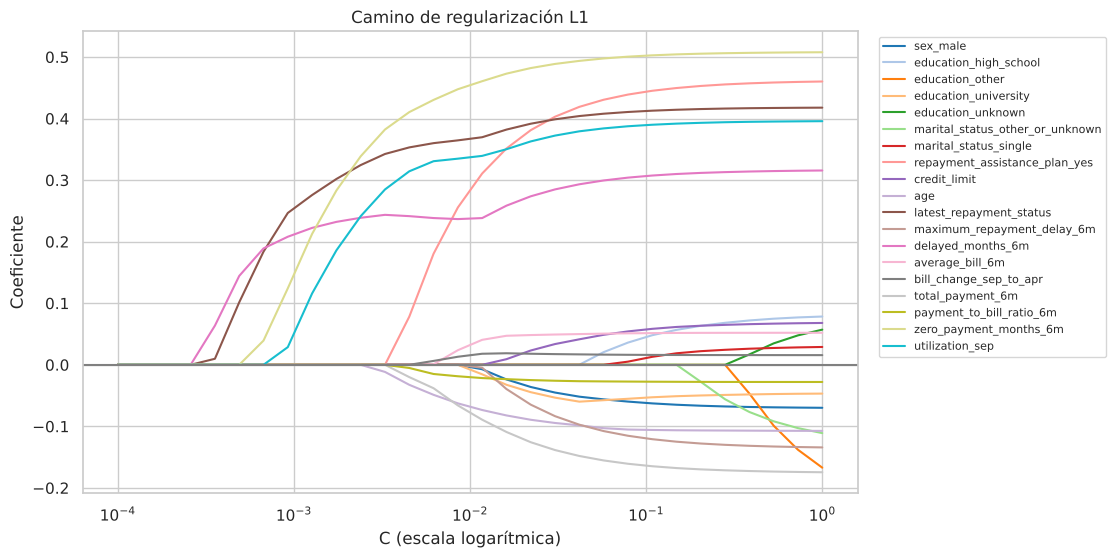

In [34]:
X_lr_std = pd.DataFrame(
    best_pipeline_lr.named_steps["preprocessor"].transform(credit_X),
    columns=lr_std_feature_names,
)

Cs_path = np.logspace(-4, 0, 30)
coefs_path = []
for C in Cs_path:
    lasso_lr = LogisticRegression(penalty="l1", solver="liblinear", C=C)
    lasso_lr.fit(X_lr_std, credit_y)
    coefs_path.append(lasso_lr.coef_[0])
coefs_path = pd.DataFrame(coefs_path, index=Cs_path, columns=lr_std_feature_names)

plt.figure(figsize=(10, 6))
for i, col in enumerate(coefs_path.columns):
    plt.plot(coefs_path.index, coefs_path[col], label=col, color=plt.cm.tab20(i))
plt.xscale("log")
plt.axhline(0, color=".5")
plt.xlabel("C (escala logarítmica)")
plt.ylabel("Coeficiente")
plt.title("Camino de regularización L1")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.savefig("lr_l1_path.png", dpi=300, bbox_inches="tight")
plt.show()

Elegimos un modelo L1 más disperso: el menor `C` con `l1_ratio=1` cuyo ROC AUC en la validación cruzada queda a menos de una desviación típica del mejor modelo.

In [35]:
res_l1 = results_lr_df[results_lr_df["param_classifier__l1_ratio"] == 1].sort_values("C")
umbral_auc = grid_search_lr.best_score_ - results_lr_df.loc[grid_search_lr.best_index_, "std_test_score"]
C_l1 = res_l1.loc[res_l1["mean_test_score"] >= umbral_auc, "C"].min()

l1_pipeline = clone(best_pipeline_lr).set_params(classifier__C=C_l1, classifier__l1_ratio=1)
l1_pipeline.fit(credit_X, credit_y)

lasso_coefs = pd.Series(l1_pipeline.named_steps["classifier"].coef_[0], index=lr_std_feature_names, name="lasso")
selected_features = lasso_coefs[lasso_coefs != 0].index

print(f"C elegido para L1: {C_l1}")
print(f"ROC AUC (CV): {res_l1.loc[res_l1['C'] == C_l1, 'mean_test_score'].iloc[0]:.4f}")
print(f"Variables seleccionadas: {len(selected_features)} de {len(lasso_coefs)}")
print(f"Variables eliminadas: {list(lasso_coefs[lasso_coefs == 0].index)}")

C elegido para L1: 0.01
ROC AUC (CV): 0.7485
Variables seleccionadas: 10 de 19
Variables eliminadas: ['sex_male', 'education_high_school', 'education_other', 'education_university', 'education_unknown', 'marital_status_other_or_unknown', 'marital_status_single', 'credit_limit', 'maximum_repayment_delay_6m']


### Selección frente a tamaño del coeficiente

La penalización L1 no solo selecciona variables: también encoge hacia cero los coeficientes que se quedan. Para verlo, reajustamos un modelo casi sin regularización usando solo las variables seleccionadas (*post-lasso refit*). Es una comprobación de sensibilidad, no una estimación definitiva, porque las variables se han elegido con los mismos datos.

In [36]:
post_lasso = LogisticRegression(C=1e6, solver="newton-cholesky", max_iter=1000)
post_lasso.fit(X_lr_std[selected_features], credit_y)

post_lasso_coefs = pd.Series(post_lasso.coef_[0], index=selected_features, name="post_lasso_refit")

coef_comparison = pd.concat([lasso_coefs.loc[selected_features], post_lasso_coefs], axis=1)
coef_comparison["abs_lasso"] = coef_comparison["lasso"].abs()
coef_comparison["abs_post_lasso_refit"] = coef_comparison["post_lasso_refit"].abs()
coef_comparison.sort_values("abs_lasso", ascending=False).round(4)

,lasso,post_lasso_refit,abs_lasso,abs_post_lasso_refit
zero_payment_months_6m,0.4612,0.4964,0.4612,0.4964
latest_repayment_status,0.3715,0.3793,0.3715,0.3793
utilization_sep,0.3415,0.3471,0.3415,0.3471
repayment_assistance_plan_yes,0.3211,0.4609,0.3211,0.4609
delayed_months_6m,0.2343,0.2323,0.2343,0.2323
total_payment_6m,-0.0824,-0.1655,0.0824,0.1655
age,-0.0697,-0.1025,0.0697,0.1025
average_bill_6m,0.0351,0.0918,0.0351,0.0918
payment_to_bill_ratio_6m,-0.0218,-0.0288,0.0218,0.0288
bill_change_sep_to_apr,0.0162,0.0333,0.0162,0.0333


Con un ROC AUC solo unas milésimas por debajo del mejor modelo, la penalización L1 se queda con 10 variables. Elimina todas las demográficas, `credit_limit` y `maximum_repayment_delay_6m`: de las variables de retraso correlacionadas se queda con las que más información aportan. Es un modelo más fácil de explicar.

Hay que tener en cuenta que una variable eliminada puede seguir relacionada con el objetivo: el modelo la descarta porque no aporta información adicional sobre las demás, y con variables correlacionadas esa selección es inestable. Además, los coeficientes que quedan están encogidos hacia cero. Por ejemplo, el de `repayment_assistance_plan_yes` pasa de ≈0.46 en el reajuste a ≈0.32 en el modelo L1, y el de `total_payment_6m` se queda en la mitad.

## Cautela con la causalidad

La regresión logística mide asociaciones estadísticas condicionales, no efectos causales:

- **`repayment_assistance_plan`**: según el diccionario de datos, el plan se asigna de forma selectiva a clientes que ya muestran señales de estrés financiero. Un coeficiente positivo indica que tener el plan está asociado a más dificultades, no que el plan las cause: lo más probable es que capture un riesgo previo que no recogen el resto de variables (variable de confusión).
- **`sex`**: es un atributo de auditoría. Su coeficiente describe una asociación en los datos históricos condicionada al resto de variables, no un efecto del sexo sobre la capacidad de pago, y usarlo para decidir puede ser discriminatorio.
- **Relaciones no lineales**: el modelo supone que el efecto de cada variable en log-odds es lineal. El diccionario advierte de que `payment_to_bill_ratio_6m` no tiene por qué tener una relación lineal con el riesgo, y algo parecido ocurre con `latest_repayment_status`, cuyos códigos negativos y cero no están documentados. El EBM permitirá ver estas formas.

## Interpretación local

Usamos las mismas cuatro instancias que en el árbol (`instancias_locales`): una correcta y una incorrecta de cada clase según el árbol. Entrenamos la regresión logística de InterpretML con los hiperparámetros óptimos sobre los datos ya preprocesados.

In [37]:
from interpret.glassbox import LogisticRegression as InterpretLogisticRegression

best_params_lr = grid_search_lr.best_params_
opt_C = best_params_lr['classifier__C']
opt_l1_ratio = best_params_lr['classifier__l1_ratio']

interpret_lr = InterpretLogisticRegression(
    penalty="elasticnet",
    solver="saga",
    C=opt_C,
    l1_ratio=opt_l1_ratio,
    max_iter=5000,
    random_state=42
)
interpret_lr.fit(X_lr_std, credit_y)

X_locales_lr = pd.DataFrame(
    best_pipeline_lr.named_steps["preprocessor"].transform(instancias_locales),
    columns=lr_std_feature_names,
    index=instancias_locales.index,
)

lr_local = interpret_lr.explain_local(X_locales_lr, y_locales, name='Regresión logística: predicciones locales')
show(lr_local)

<!-- http://127.0.0.1:7001/140061507767328/ -->

La contribución de cada variable a una predicción es $\beta_i x_i$ (en log-odds). Sumando el intercepto y todas las contribuciones obtenemos el log-odds de la instancia.

In [38]:
contribuciones = X_locales_lr * fitted_lr.coef_[0]

resumen_locales = pd.DataFrame({
    "Clase real": y_locales,
    "Pred. árbol": best_pipeline.predict(instancias_locales),
    "Prob. regresión logística": best_pipeline_lr.predict_proba(instancias_locales)[:, 1].round(3),
    "Pred. RL (umbral 0.5)": best_pipeline_lr.predict(instancias_locales),
    f"Pred. RL (umbral {umbral_bal})": (best_pipeline_lr.predict_proba(instancias_locales)[:, 1] >= umbral_bal).astype(int),
}, index=instancias_locales.index)
resumen_locales

,Clase real,Pred. árbol,Prob. regresión logística,Pred. RL (umbral 0.5),Pred. RL (umbral 0.23)
Clase 0 - Prediccion Correcta (True Neg),0,0,0.077,0,0
Clase 0 - Prediccion Incorrecta (False Pos),0,1,0.441,0,1
Clase 1 - Prediccion Correcta (True Pos),1,1,0.516,1,1
Clase 1 - Prediccion Incorrecta (False Neg),1,0,0.320,0,1


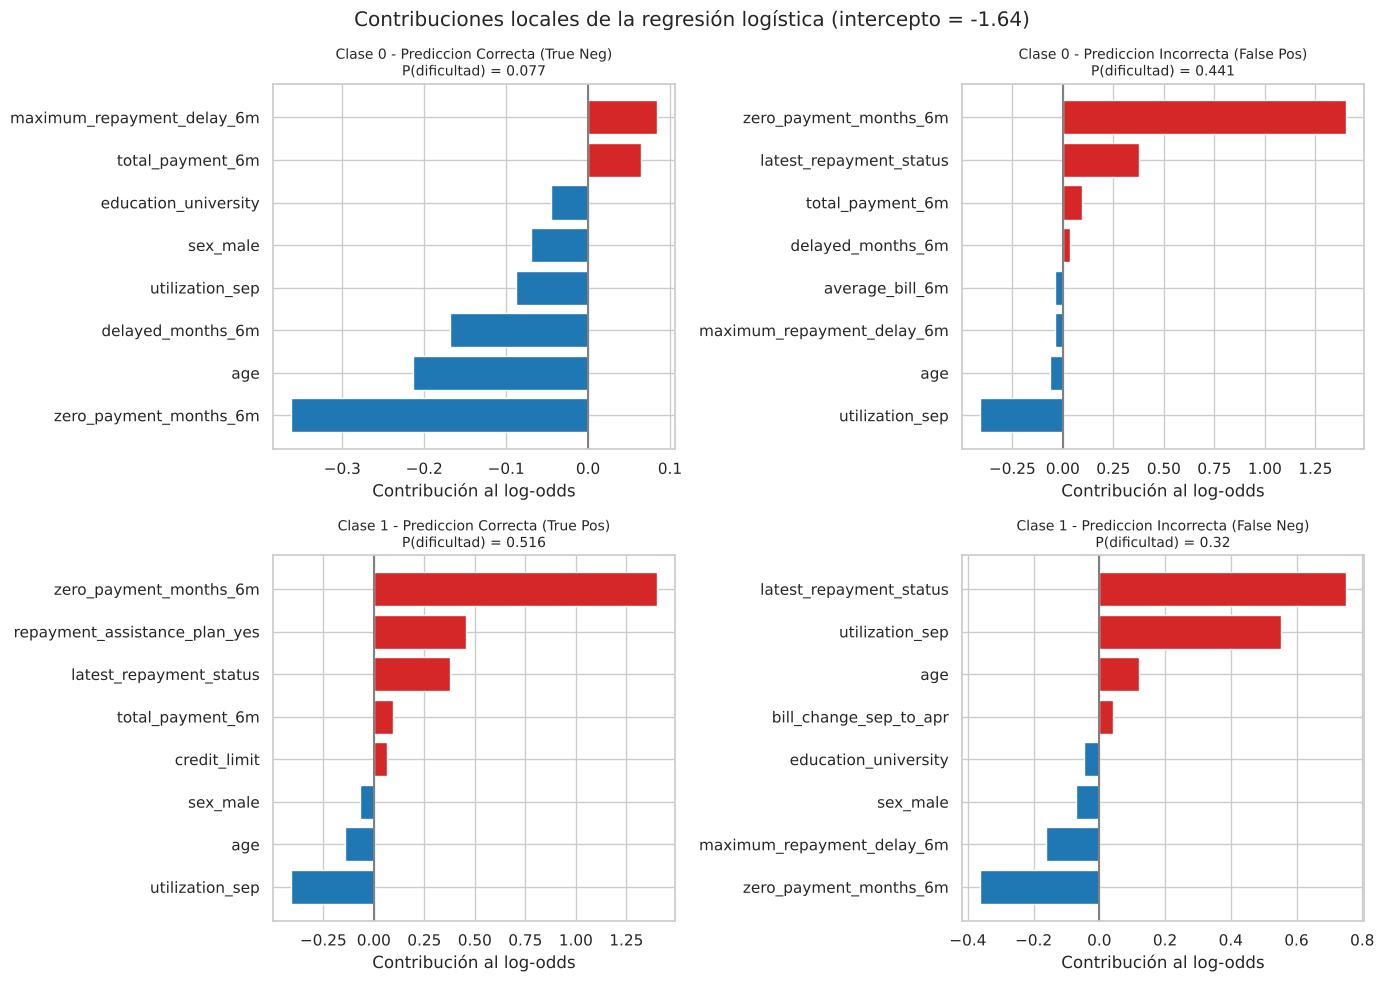

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (nombre, fila) in zip(axes.ravel(), contribuciones.iterrows()):
    top = fila.reindex(fila.abs().sort_values(ascending=False).index[:8]).sort_values()
    colores = ["tab:red" if v > 0 else "tab:blue" for v in top]
    ax.barh(top.index, top.values, color=colores)
    ax.axvline(0, color=".5")
    prob = resumen_locales.loc[nombre, "Prob. regresión logística"]
    ax.set_title(f"{nombre}\nP(dificultad) = {prob}", fontsize=10)
    ax.set_xlabel("Contribución al log-odds")
plt.suptitle(f"Contribuciones locales de la regresión logística (intercepto = {fitted_lr.intercept_[0]:.2f})")
plt.tight_layout()
plt.savefig("lr_local.png", dpi=300, bbox_inches="tight")
plt.show()

- **Clase 0, acierto**: no tiene retrasos, ha pagado todos los meses (`zero_payment_months_6m` = 0 resta) y la edad también resta. Probabilidad muy baja (≈0.08).
- **Clase 0, fallo del árbol**: seis meses sin pagar suman mucho (≈+1.4), pero su factura y su utilización son prácticamente cero. Es una cuenta casi inactiva: no paga porque no debe nada. La regresión logística acierta con el umbral 0.5 (≈0.44), aunque se equivocaría con el umbral 0.23. Que no pagar solo sea preocupante cuando hay factura es una interacción que un modelo aditivo lineal no puede representar.
- **Clase 1, acierto**: su perfil es casi idéntico al anterior (sin factura, seis meses sin pagar, estado 1). La diferencia principal es que tiene el plan de asistencia (+0.46), que lo lleva por encima de 0.5. Muestra lo mucho que pesa esa variable, que en realidad refleja un riesgo previo detectado por el banco.
- **Clase 1, fallo del árbol**: tiene un estado de pago reciente de 2 meses de retraso (≈+0.75) y la utilización casi al máximo (≈+0.55), pero paga todos los meses y es joven. El modelo le da ≈0.32: no lo detecta con el umbral 0.5 (igual que el árbol), pero sí con el umbral que maximiza el balanced accuracy.

Resumen para la tabla de resultados

In [40]:
pd.DataFrame([{
    "Classifier": "LogisticRegression",
    "Key settings": f"penalty=elasticnet, C={opt_C}, l1_ratio={opt_l1_ratio}, numéricas estandarizadas",
    **{f"CV {m}": f"{cv_results_lr[f'test_{m}'].mean():.4f} ± {cv_results_lr[f'test_{m}'].std():.4f}" for m in scoring_metrics},
}])

,Classifier,Key settings,CV accuracy,CV balanced_accuracy,CV recall,CV roc_auc
0,LogisticRegression,"penalty=elasticnet, C=0.1, l1_ratio=0, numéric...",0.8106 ± 0.0031,0.6038 ± 0.0062,0.2446 ± 0.0118,0.7518 ± 0.0055
